In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("E-Commerce Sales Analysis Project Started!")

E-Commerce Sales Analysis Project Started!


In [3]:
import pandas as pd
df=pd.read_csv(r"C:\Users\AT Laptops\OneDrive\Documents\GitHub\Data-Analytics-Portfolio\E-Commerce-Sales-Analysis\Data\ecommerce_sales.csv")
df

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price
0,1001,2026-01-05,Amit,Delhi,Laptop,Electronics,1,55000
1,1002,2026-01-08,Priya,Mumbai,Mobile,Electronics,2,18000
2,1003,2026-01-12,Rahul,Pune,Chair,Furniture,4,2500
3,1004,2026-01-15,Neha,Delhi,Table,Furniture,2,6000
4,1005,2026-01-20,Rohit,Jaipur,Headphones,Accessories,3,1500
5,1006,2026-02-03,Sneha,Mumbai,Laptop,Electronics,1,60000
6,1007,2026-02-07,Vikas,Pune,Mobile,Electronics,3,20000
7,1008,2026-02-11,Anjali,Delhi,Chair,Furniture,5,2200
8,1009,2026-02-18,Karan,Jaipur,Keyboard,Accessories,4,1200
9,1010,2026-02-25,Pooja,Mumbai,Table,Furniture,1,7000


In [4]:
df.shape

(25, 8)

In [5]:
df.columns.tolist()

['Order_ID',
 'Order_Date',
 'Customer_Name',
 'City',
 'Product',
 'Category',
 'Quantity',
 'Unit_Price']

# Check Data Types and Missing Values

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Order_ID       25 non-null     int64
 1   Order_Date     25 non-null     str  
 2   Customer_Name  25 non-null     str  
 3   City           25 non-null     str  
 4   Product        25 non-null     str  
 5   Category       25 non-null     str  
 6   Quantity       25 non-null     int64
 7   Unit_Price     25 non-null     int64
dtypes: int64(3), str(5)
memory usage: 2.6 KB


# Statistical Summary

In [7]:
df.describe()

,Order_ID,Quantity,Unit_Price
count,25.000000,25.000000,25.000000
mean,1013.000000,2.640000,18160.000000
std,7.359801,1.410674,21758.504085
min,1001.000000,1.000000,1200.000000
25%,1007.000000,2.000000,2200.000000
50%,1013.000000,2.000000,6800.000000
75%,1019.000000,3.000000,21000.000000
max,1025.000000,6.000000,62000.000000


# Calculate Total Sales

In [8]:
df["Total_Sales"]=df["Quantity"]*df["Unit_Price"]
df.head()

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,1001,2026-01-05,Amit,Delhi,Laptop,Electronics,1,55000,55000
1,1002,2026-01-08,Priya,Mumbai,Mobile,Electronics,2,18000,36000
2,1003,2026-01-12,Rahul,Pune,Chair,Furniture,4,2500,10000
3,1004,2026-01-15,Neha,Delhi,Table,Furniture,2,6000,12000
4,1005,2026-01-20,Rohit,Jaipur,Headphones,Accessories,3,1500,4500


# Overall Sales Analysis

In [9]:
Total_revenue=df["Total_Sales"].sum()
print("Total Revenue:",Total_revenue)

Total Revenue: 726100


# Average Order Value

In [11]:
average_order_value=df["Total_Sales"].mean()
print("Average Order Value:", round(average_order_value,2))

Average Order Value: 29044.0


# City-wise Sales Analysis

In [12]:
city_sales=df.groupby("City")["Total_Sales"].sum()
city_sales

City
Delhi     244100
Jaipur     75400
Mumbai    230200
Pune      176400
Name: Total_Sales, dtype: int64

In [13]:
city_sales.sort_values(ascending=False)

City
Delhi     244100
Mumbai    230200
Pune      176400
Jaipur     75400
Name: Total_Sales, dtype: int64

In [14]:
print("Highest Sales City:", city_sales.idxmax())
print("Highest City Sales:", city_sales.max())

Highest Sales City: Delhi
Highest City Sales: 244100


# Category-wise Sales Analysis

In [15]:
category_sales=df.groupby("Category")["Total_Sales"].sum()
category_sales

Category
Accessories     31500
Electronics    600500
Furniture       94100
Name: Total_Sales, dtype: int64

In [16]:
category_sales.sort_values(ascending=False)

Category
Electronics    600500
Furniture       94100
Accessories     31500
Name: Total_Sales, dtype: int64

In [17]:
print("Highest Sales Category:", category_sales.idxmax())
print("Highest Category Sales:", category_sales.max())

Highest Sales Category: Electronics
Highest Category Sales: 600500


# Product-wise Sales Analysis

In [18]:
product_sales=df.groupby("Product")["Total_Sales"].sum()
product_sales.sort_values(ascending=False)

Product
Laptop        349000
Mobile        251500
Table          52100
Chair          42000
Headphones     19900
Keyboard       11600
Name: Total_Sales, dtype: int64

In [19]:
print("Best-Selling Product:", product_sales.idxmax())
print("Highest Product Sales:", product_sales.max())

Best-Selling Product: Laptop
Highest Product Sales: 349000


# Monthly Sales Analysis

In [20]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Month"] = df["Order_Date"].dt.month_name()

monthly_sales = df.groupby("Month")["Total_Sales"].sum()

monthly_sales

Month
April       174700
February    142800
January     117500
March       120800
May         170300
Name: Total_Sales, dtype: int64

In [21]:
monthly_sales.sort_values(ascending=False)

Month
April       174700
May         170300
February    142800
March       120800
January     117500
Name: Total_Sales, dtype: int64

In [22]:
print("Highest Sales Month:", monthly_sales.idxmax())
print("Highest Monthly Sales:", monthly_sales.max())

Highest Sales Month: April
Highest Monthly Sales: 174700


# Monthly Sales Visualization

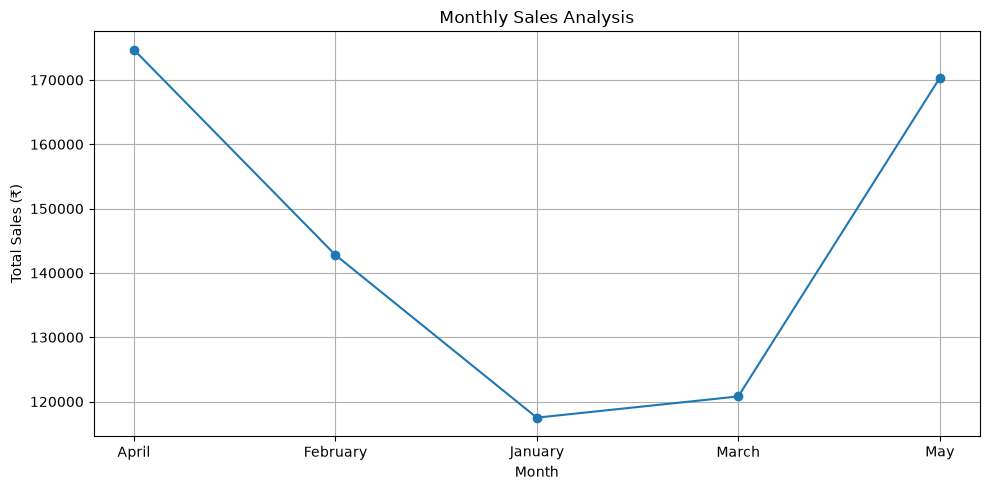

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")

plt.grid(True)
plt.tight_layout()
plt.show()

# Category-wise Sales Visualization

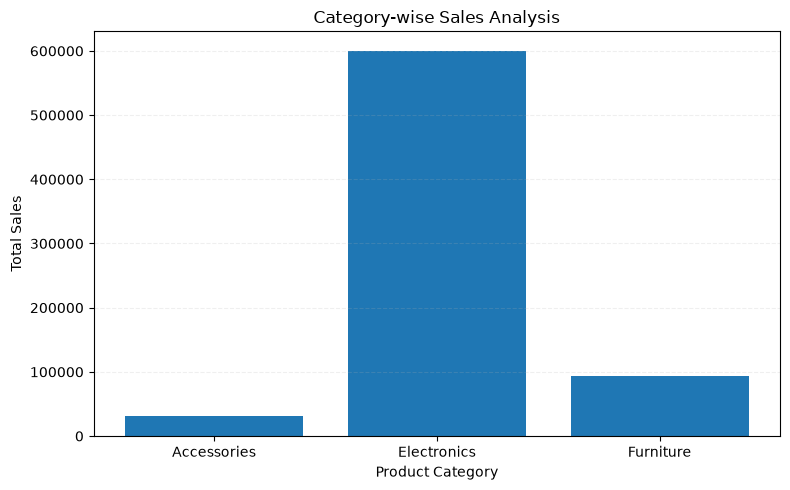

In [32]:
plt.figure(figsize=(8,5))

plt.bar(category_sales.index, category_sales.values)

plt.title("Category-wise Sales Analysis")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.grid(axis="y", linestyle="--", alpha=0.2)

plt.tight_layout()
plt.show()

# Top 5 Highest Revenue Orders

In [33]:
top_5_orders = df.nlargest(5, "Total_Sales")

top_5_orders[["Order_ID", "Customer_Name", "Product", "City", "Total_Sales"]]

,Order_ID,Customer_Name,Product,City,Total_Sales
17,1018,Rahul,Laptop,Mumbai,114000
23,1024,Karan,Laptop,Delhi,62000
5,1006,Sneha,Laptop,Mumbai,60000
6,1007,Vikas,Mobile,Pune,60000
11,1012,Meena,Laptop,Pune,58000


# Top 5 Customers by Revenue

In [34]:
customer_sales = df.groupby("Customer_Name")["Total_Sales"].sum()

top_5_customers = customer_sales.sort_values(ascending=False).head(5)

top_5_customers

Customer_Name
Rahul    124000
Sneha     98000
Amit      76000
Karan     66800
Vikas     64200
Name: Total_Sales, dtype: int64

# Visualization

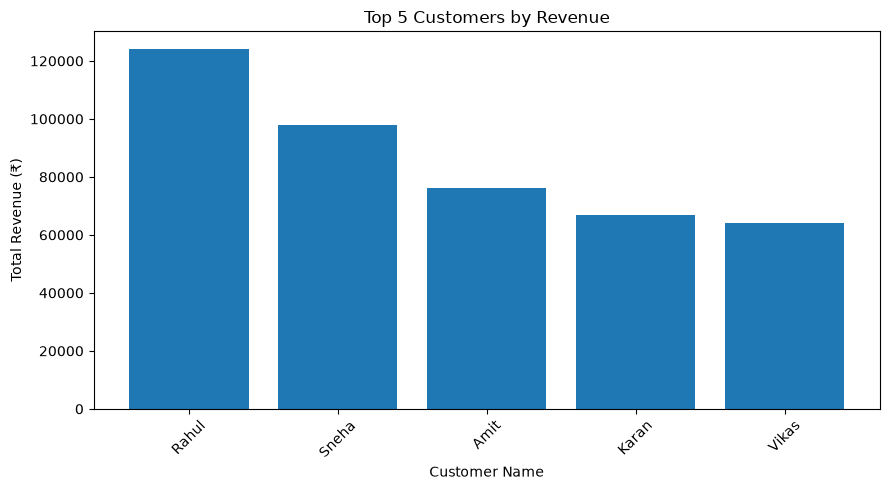

In [35]:
plt.figure(figsize=(9, 5))

plt.bar(top_5_customers.index, top_5_customers.values)

plt.title("Top 5 Customers by Revenue")
plt.xlabel("Customer Name")
plt.ylabel("Total Revenue (₹)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Product-wise Quantity Analysis

In [36]:
product_quantity = df.groupby("Product")["Quantity"].sum()

product_quantity.sort_values(ascending=False)

Product
Chair         18
Mobile        13
Headphones    12
Keyboard       9
Table          8
Laptop         6
Name: Quantity, dtype: int64

# Find the Most Sold Product

In [37]:
print("Most Sold Product:", product_quantity.idxmax())
print("Total Quantity Sold:", product_quantity.max())

Most Sold Product: Chair
Total Quantity Sold: 18


# Sales Distribution by Product

In [38]:
product_sales = df.groupby("Product")["Total_Sales"].sum()

product_sales

Product
Chair          42000
Headphones     19900
Keyboard       11600
Laptop        349000
Mobile        251500
Table          52100
Name: Total_Sales, dtype: int64

# Calculate Percentage Contribution

In [39]:
sales_percentage = (product_sales / df["Total_Sales"].sum()) * 100

sales_percentage.round(2)

Product
Chair          5.78
Headphones     2.74
Keyboard       1.60
Laptop        48.07
Mobile        34.64
Table          7.18
Name: Total_Sales, dtype: float64

# Create a Pie Chart

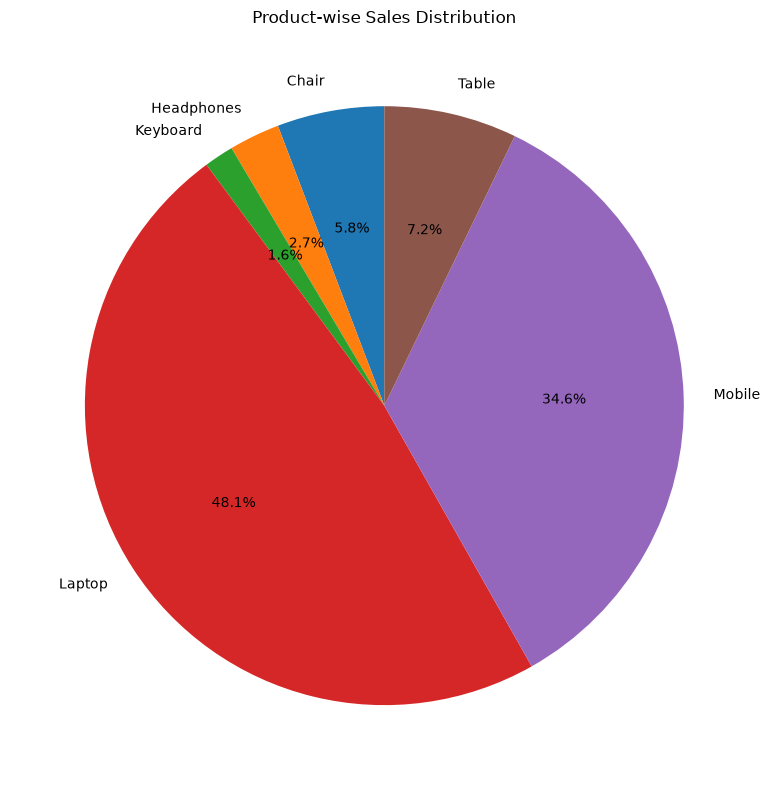

In [40]:
plt.figure(figsize=(8, 8))

plt.pie(
    product_sales.values,
    labels=product_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Product-wise Sales Distribution")
plt.tight_layout()
plt.show()

# Sales and Profit Analysis

# Revenue Analysis by Category

# Calculate Total Revenue by Category

In [41]:
category_revenue = df.groupby("Category")["Total_Sales"].sum()

category_revenue

Category
Accessories     31500
Electronics    600500
Furniture       94100
Name: Total_Sales, dtype: int64

# Calculate Revenue Percentage by Category

In [42]:
category_percentage = (
    category_revenue / df["Total_Sales"].sum()
) * 100

category_percentage.round(2)

Category
Accessories     4.34
Electronics    82.70
Furniture      12.96
Name: Total_Sales, dtype: float64

# Visualize Revenue Percentage

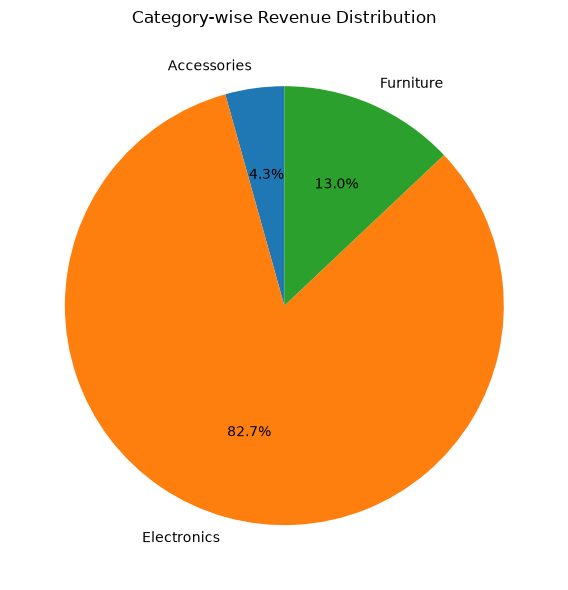

In [43]:
plt.figure(figsize=(8, 6))

plt.pie(
    category_revenue.values,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category-wise Revenue Distribution")
plt.tight_layout()
plt.show()

# Order Quantity Analysis

# Calculate Total Quantity by Product

In [44]:
product_quantity = df.groupby("Product")["Quantity"].sum()

product_quantity.sort_values(ascending=False)

Product
Chair         18
Mobile        13
Headphones    12
Keyboard       9
Table          8
Laptop         6
Name: Quantity, dtype: int64

# Visualize Product Quantity

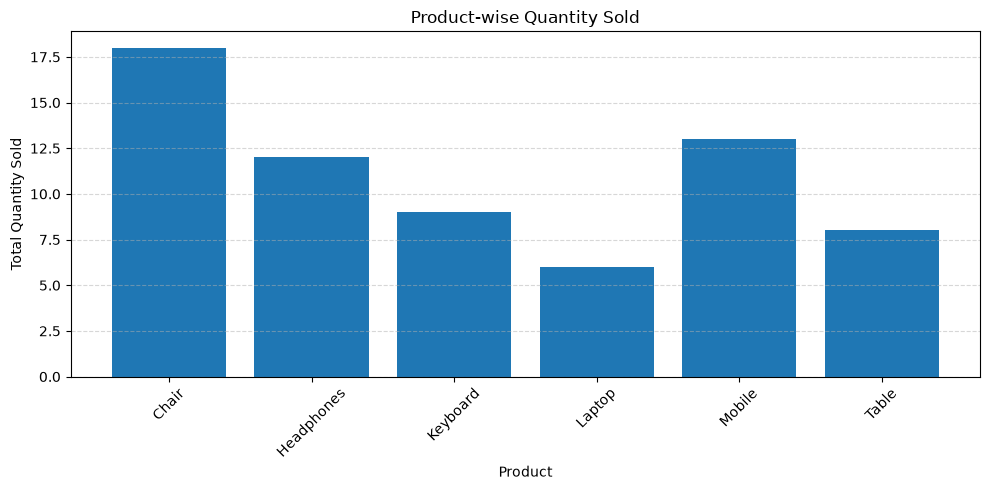

In [45]:
plt.figure(figsize=(10, 5))

plt.bar(product_quantity.index, product_quantity.values)

plt.title("Product-wise Quantity Sold")
plt.xlabel("Product")
plt.ylabel("Total Quantity Sold")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Daily Sales Analysis

# Calculate Daily Revenue 

In [46]:
daily_sales = df.groupby("Order_Date")["Total_Sales"].sum()

daily_sales

Order_Date
2026-01-05     55000
2026-01-08     36000
2026-01-12     10000
2026-01-15     12000
2026-01-20      4500
2026-02-03     60000
2026-02-07     60000
2026-02-11     11000
2026-02-18      4800
2026-02-25      7000
2026-03-02     44000
2026-03-09     58000
2026-03-14      7200
2026-03-19      9000
2026-03-25      2600
2026-04-04     21000
2026-04-10     19500
2026-04-16    114000
2026-04-21      6400
2026-04-28     13800
2026-05-03     38000
2026-05-09      4200
2026-05-15     13600
2026-05-22     62000
2026-05-29     52500
Name: Total_Sales, dtype: int64

# Find the Highest Revenue Date

In [47]:
print("Highest Revenue Date:", daily_sales.idxmax())
print("Highest Daily Revenue:", daily_sales.max())

Highest Revenue Date: 2026-04-16 00:00:00
Highest Daily Revenue: 114000


# Visualize Daily Sales

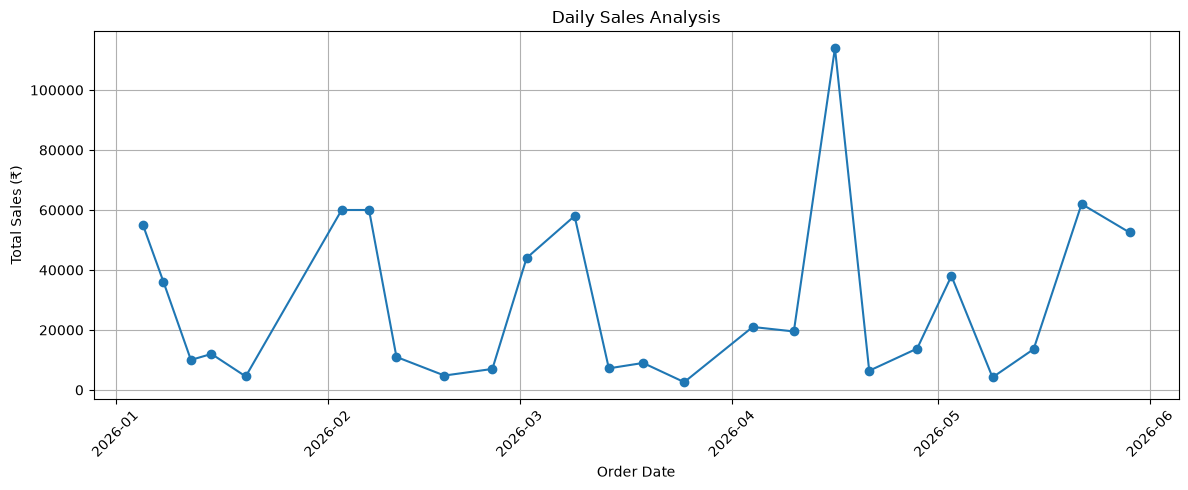

In [48]:
plt.figure(figsize=(12, 5))

plt.plot(daily_sales.index, daily_sales.values, marker="o")

plt.title("Daily Sales Analysis")
plt.xlabel("Order Date")
plt.ylabel("Total Sales (₹)")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

# Sales Performance Summary

In [49]:
total_revenue = df["Total_Sales"].sum()
total_orders = df["Order_ID"].nunique()
total_quantity = df["Quantity"].sum()
average_order_value = df["Total_Sales"].mean()
total_customers = df["Customer_Name"].nunique()

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value:", round(average_order_value, 2))
print("Total Unique Customers:", total_customers)

Total Revenue: 726100
Total Orders: 25
Total Quantity Sold: 66
Average Order Value: 29044.0
Total Unique Customers: 15


# Sales Summary Dashboard

In [50]:
total_revenue = df["Total_Sales"].sum()
total_orders = df["Order_ID"].nunique()
total_quantity = df["Quantity"].sum()
average_order_value = df["Total_Sales"].mean()
total_customers = df["Customer_Name"].nunique()

print("========== SALES SUMMARY ==========")
print("Total Revenue:", f"₹{total_revenue:,.2f}")
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value:", f"₹{average_order_value:,.2f}")
print("Total Unique Customers:", total_customers)
print("===================================")

========== SALES SUMMARY ==========
Total Revenue: ₹726,100.00
Total Orders: 25
Total Quantity Sold: 66
Average Order Value: ₹29,044.00
Total Unique Customers: 15


# Visualize Revenue by City

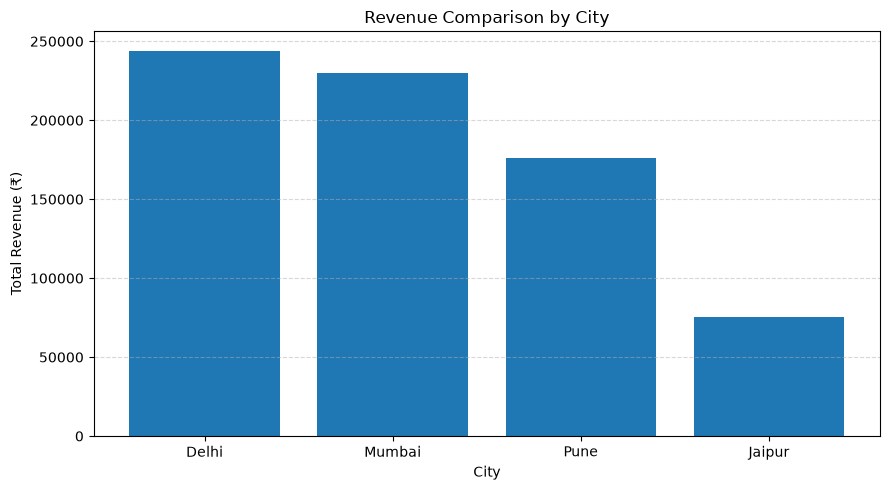

In [51]:
city_sales = df.groupby("City")["Total_Sales"].sum()
city_sales = city_sales.sort_values(ascending=False)

plt.figure(figsize=(9, 5))

plt.bar(city_sales.index, city_sales.values)

plt.title("Revenue Comparison by City")
plt.xlabel("City")
plt.ylabel("Total Revenue (₹)")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Visualize Monthly Revenue 

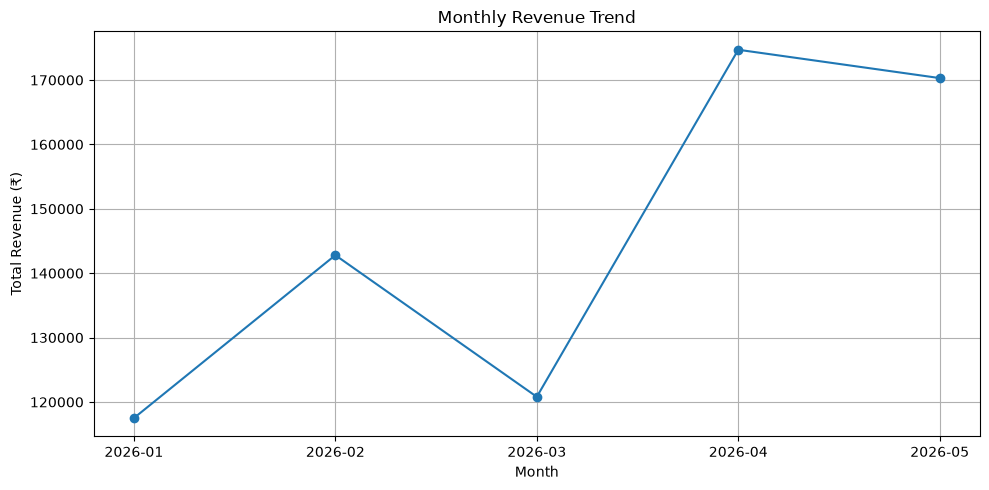

In [52]:
monthly_sales = df.groupby(
    df["Order_Date"].dt.to_period("M")
)["Total_Sales"].sum()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")

plt.grid(True)
plt.tight_layout()
plt.show()

# Export the Final Analysis Dataset

In [54]:
df.to_csv("ecommerce_sales_analyzed.csv", index=False)

print("Analysis dataset saved successfully!")

Analysis dataset saved successfully!


# Key Business Insights

## 23. Key Business Insights

- Delhi generated the highest revenue among all cities.
- Electronics was the highest-revenue product category.
- Accessories generated the lowest revenue among the categories.
- Laptop generated the highest total revenue among individual products.
- Chair had the highest total quantity sold.
- April recorded the highest monthly revenue.
- The analysis helps identify customer purchasing patterns and sales trends.

# Conclusion

## 24. Conclusion

This project analyzes e-commerce sales data using Python, Pandas, NumPy, and Matplotlib.

The analysis explores sales trends, product performance, category-wise revenue, city-wise sales, and customer purchasing patterns.

The findings help identify top-performing products, high-revenue cities, and monthly sales trends. This project demonstrates how data analysis can support better business decisions.

In [1]:
import os
print(os.path.abspath("ecommerce_sales_analyzed.csv"))

C:\Users\AT Laptops\OneDrive\Documents\GitHub\Data-Analytics-Portfolio\E-Commerce-Sales-Analysis\Data\ecommerce_sales_analyzed.csv
